In [1]:
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"CUDA Version: {torch.version.cuda}")
print(f"GPU Name: {torch.cuda.get_device_name(0)}")

PyTorch Version: 2.5.1+cu121
CUDA Available: True
CUDA Version: 12.1
GPU Name: NVIDIA RTX A4000


In [2]:
# ============================================================
# Step 1: Environment, Imports, Reproducibility, and Runtime Setup
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid
# Target Dataset: CamVid
# Optimization Mode: VRAM-Armored Mixed Precision Fine-Tuning
# ============================================================

import os
import gc
import math
import glob
import time
import random
import warnings
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.metrics import confusion_matrix
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
from transformers import Mask2FormerConfig, Mask2FormerForUniversalSegmentation

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from torch.utils.data import Dataset, DataLoader
from torch.amp import GradScaler, autocast
from torch.utils.checkpoint import checkpoint 

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42

def set_seed(seed: int = 42, deterministic: bool = False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        try:
            torch.use_deterministic_algorithms(True)
        except Exception:
            pass
    else:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True

set_seed(SEED, deterministic=False)

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    torch.manual_seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)

%matplotlib inline
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 600
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_style("whitegrid")
sns.set_context("talk", font_scale=0.9)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
    try:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    except Exception:
        pass

PHYSICAL_BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 8  
USE_AMP = torch.cuda.is_available()
scaler = GradScaler("cuda" if torch.cuda.is_available() else "cpu", enabled=USE_AMP)

CAMVID_ROOT = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/CamVid")
FINAL_SAVE_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/Results_Export") 
QUAL_VIS_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/training_visuals")

CHECKPOINT_DIR = FINAL_SAVE_DIR / "progressive_checkpoints_sgdw_v2_cv"
PLOTS_DIR = FINAL_SAVE_DIR / "training_plots_sgdw_v2_cv"
LOGS_DIR = FINAL_SAVE_DIR / "training_logs_sgdw_v2_cv"
METRICS_DIR = FINAL_SAVE_DIR / "training_metrics_sgdw_v2_cv"

for directory in [CHECKPOINT_DIR, PLOTS_DIR, LOGS_DIR, METRICS_DIR, FINAL_SAVE_DIR, QUAL_VIS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "facebook/mask2former-swin-small-cityscapes-semantic"
MODEL_ALIAS = "Semantically Guided Deformable Window (Pixel Decoder) - Swin-Small"

history = {
    "epoch": [],
    "phase": [],
    "train_total_loss": [],
    "train_boundary_loss": [], 
    "train_miou": [],    
    "train_macc": [],    
    "train_aacc": [],    
    "val_total_loss": [],
    "val_miou": [],
    "val_macc": [],
    "val_aacc": [],
    "backbone_lr": [],
    "head_lr": [],
    "sgdw_offset_magnitude": [], 
    "sgdw_dynamic_bound": [],    
    "epoch_time_sec": [],
    "total_training_time_str": []
}

best_record = {
    "epoch": -1,
    "best_epoch": -1,
    "best_miou": -1.0,
    "best_macc": -1.0,
    "best_aacc": -1.0,
    "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_cv.pt"),
    "latest_path": str(CHECKPOINT_DIR / "latest_model_sgdw_cv.pt")
}

def save_checkpoint(epoch, model, optimizer_backbone, optimizer_head, scaler, scheduler, history_dict, total_time, is_best=False):
    state = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_backbone_state_dict': optimizer_backbone.state_dict(),
        'optimizer_head_state_dict': optimizer_head.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'scheduler_state_dict': scheduler.state_dict() if scheduler else None,
        'history': history_dict,
        'total_training_time': total_time,
        'best_record': best_record
    }
    
    torch.save(state, best_record['latest_path'])
    
    if is_best:
        torch.save(state, best_record['best_path'])

Device: cuda
GPU: NVIDIA RTX A4000
CUDA Version: 12.1
GPU Memory: 15.73 GB


In [5]:
# ============================================================
# STEP 2: HYPERPARAMETERS, LABEL ENCODING, VISUALIZATION
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid
# Target Dataset: CamVid
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import torch
import torch.nn.functional as F

IMG_ROOT = CAMVID_ROOT / "train"
MASK_ROOT = CAMVID_ROOT / "train_labels"

print(f"Image root linked: {IMG_ROOT}")
print(f"Mask root linked : {MASK_ROOT}")
print(f"Visualizations target: {QUAL_VIS_DIR.resolve()}")
print(f"Final export target: {FINAL_SAVE_DIR.resolve()}")

# ------------------------------------------------------------
# CORE TASK SETTINGS (CamVid 11-Class Standard)
# ------------------------------------------------------------
CLASSES = 11
IGNORE_INDEX = 255
USE_LABEL_TRAINIDS = True

CLASS_NAMES = [
    "Sky", "Building", "Pole", "Road", "Pavement", 
    "Tree", "SignSymbol", "Fence", "Car", "Pedestrian", "Bicyclist"
]

CAMVID_PALETTE = np.array([
    [128, 128, 128],  
    [128, 0, 0],      
    [192, 192, 128],  
    [128, 64, 128],   
    [60, 40, 222],    
    [128, 128, 0],    
    [192, 128, 128],  
    [64, 64, 128],    
    [64, 0, 128],     
    [64, 64, 0],      
    [0, 128, 192]     
], dtype=np.uint8)

# ------------------------------------------------------------
# IMAGE GEOMETRY (Adapted for Swin 32x Downsampling Requirement)
# ------------------------------------------------------------
IMG_H = 704
IMG_W = 960
VAL_IMG_H = 704  
VAL_IMG_W = 960  

# ------------------------------------------------------------
# EPOCHS & TRIPARTITE SGDW OPTIMIZATION SCHEDULE
# ------------------------------------------------------------
EPOCHS = 120
USE_EARLY_STOPPING = False  

BASE_HEAD_LR = 1e-4        
BACKBONE_LR = 1e-5         
SGDW_OFFSET_LR = 1e-5     

WARMUP_EPOCHS = 3         
WEIGHT_DECAY = 0.05       
GRAD_CLIP_NORM = 0.01     

print("\n--- SGDW Swin-Small Multi-Rate Fine-Tuning Schedule ---")
print(f"Total Training Epochs: {EPOCHS}")
print(f"Linear Warmup Period  : {WARMUP_EPOCHS} Epochs")
print(f"Decoder Head LR       : {BASE_HEAD_LR}")
print(f"Swin Backbone LR      : {BACKBONE_LR}")
print(f"SGDW Offset Net LR    : {SGDW_OFFSET_LR}")

# ------------------------------------------------------------
# VALIDATION / INFERENCE SETTINGS
# ------------------------------------------------------------
USE_SLIDING_WINDOW_VAL = True
VAL_WINDOW_SIZE = (704, 960)
VAL_WINDOW_STRIDE = (512, 512)   
USE_FLIP_TTA = True              

# ------------------------------------------------------------
# SCHEDULER / LOSS SETTINGS
# ------------------------------------------------------------
DICE_WEIGHT = 5.0
MASK_WEIGHT = 5.0
CE_WEIGHT = 2.0

USE_BOUNDARY_LOSS = True
BOUNDARY_LOSS_WEIGHT = 0.25 

# ------------------------------------------------------------
# LABEL ENCODING & DECODING (CamVid Specific)
# ------------------------------------------------------------
def encode_mask(mask: np.ndarray) -> np.ndarray:
    if len(mask.shape) == 2:
        return mask.astype(np.uint8)
    
    encoded = np.full((mask.shape[0], mask.shape[1]), IGNORE_INDEX, dtype=np.uint8)
    for i, color in enumerate(CAMVID_PALETTE):
        match = np.all(mask == color, axis=-1)
        encoded[match] = i
    return encoded

def decode_segmap(segmentation_map: np.ndarray) -> np.ndarray:
    h, w = segmentation_map.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    valid_mask = (segmentation_map >= 0) & (segmentation_map < CLASSES)
    for label, color in enumerate(CAMVID_PALETTE):
        rgb[segmentation_map == label] = color
    rgb[~valid_mask] = np.array([0, 0, 0], dtype=np.uint8)
    return rgb

# ------------------------------------------------------------
# PUBLICATION-READY EVALUATION CURVES
# ------------------------------------------------------------
def plot_training_curves(history_dict, save_path=FINAL_SAVE_DIR):
    keys_to_extract = ['epoch', 'train_total_loss', 'val_total_loss', 'train_miou', 'val_miou']
    safe_dict = {}
    
    target_len = len(history_dict.get('epoch', []))
    if target_len == 0: return

    for k in keys_to_extract:
        if k in history_dict:
            col = history_dict[k]
            if len(col) > target_len:
                safe_dict[k] = col[:target_len]
            elif len(col) < target_len:
                safe_dict[k] = col + [np.nan] * (target_len - len(col))
            else:
                safe_dict[k] = col
        else:
            safe_dict[k] = [np.nan] * target_len

    df = pd.DataFrame(safe_dict)
    interval_df = df[(df['epoch'] % 5 == 0) | (df['epoch'] == df['epoch'].max())]
    epochs_filtered = interval_df['epoch'].values

    sns.set_theme(style="darkgrid")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].plot(epochs_filtered, interval_df["train_total_loss"], marker='o', label='Train Loss', color='blue', linewidth=2)
    if not interval_df["val_total_loss"].isna().all():
        axes[0].plot(epochs_filtered, interval_df["val_total_loss"], marker='s', label='Validation Loss', color='red', linewidth=2)
    axes[0].set_title('Loss Progress', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    
    if epochs_filtered.max() >= WARMUP_EPOCHS:
        axes[0].axvline(x=WARMUP_EPOCHS, color='black', linestyle='--', label='Warmup End')
    axes[0].legend(fontsize=12)

    axes[1].plot(epochs_filtered, interval_df["train_miou"] * 100, marker='o', label='Train mIoU', color='green', linewidth=2)
    if not interval_df["val_miou"].isna().all():
        axes[1].plot(epochs_filtered, interval_df["val_miou"] * 100, marker='s', label='Validation mIoU', color='orange', linewidth=2)
    
    axes[1].set_title('mIoU Progress (5-Epoch Intervals)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('mIoU', fontsize=12)
    axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=2))
    
    if epochs_filtered.max() >= WARMUP_EPOCHS:
        axes[1].axvline(x=WARMUP_EPOCHS, color='black', linestyle='--', label='Warmup End')
    axes[1].legend(fontsize=12)

    plt.tight_layout()
    combined_graph_path = save_path / "presentation_metrics_progress_sgdw_camvid.png"
    plt.savefig(combined_graph_path, dpi=600, bbox_inches="tight")
    plt.close()

# ------------------------------------------------------------
# QUALITATIVE VISUALIZATION
# ------------------------------------------------------------
def visualize_results(loader, model, epoch, save_path=QUAL_VIS_DIR, max_images=3):
    save_path = Path(save_path)
    save_path.mkdir(parents=True, exist_ok=True)
    model.eval()

    batch = next(iter(loader))
    images, mask_labels, class_labels = batch
    images = images.to(DEVICE)
    _, _, current_h, current_w = images.shape

    with torch.no_grad():
        with torch.autocast(device_type="cuda", enabled=(torch.cuda.is_available() and images.is_cuda)):
            outputs = model(pixel_values=images)
            mask_preds = F.interpolate(outputs.masks_queries_logits, size=(current_h, current_w), mode="bilinear", align_corners=False)
            mask_cls = outputs.class_queries_logits.softmax(dim=-1)[..., :-1]
            semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
            preds = torch.argmax(semantic_logits, dim=1).cpu().numpy()

    images_np = images.detach().cpu().numpy()
    targets = np.full((len(images_np), current_h, current_w), IGNORE_INDEX, dtype=np.uint8)

    for batch_idx in range(len(class_labels)):
        for inst_idx, class_id in enumerate(class_labels[batch_idx]):
            cls_id = int(class_id.item())
            if cls_id != IGNORE_INDEX and 0 <= cls_id < CLASSES:
                instance_mask = mask_labels[batch_idx][inst_idx].cpu().numpy() == 1
                targets[batch_idx][instance_mask] = cls_id

    n = min(max_images, len(images_np))
    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))
    if n == 1: axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        img = np.transpose(images_np[i], (1, 2, 0))
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img = np.clip(img, 0, 1)

        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Input Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(decode_segmap(targets[i]))
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(decode_segmap(preds[i]))
        axes[i, 2].set_title(f"SGDW Prediction (Epoch {epoch})")
        axes[i, 2].axis("off")

    plt.tight_layout()
    out_file = save_path / f"epoch_{epoch:03d}_comparison.png"
    plt.savefig(out_file, dpi=600, bbox_inches="tight")
    plt.close(fig)

def save_visuals_every_10_epochs(epoch, loader, model, save_path=QUAL_VIS_DIR, max_images=3):
    if epoch % 10 == 0:
        visualize_results(loader, model, epoch, save_path, max_images)

# ------------------------------------------------------------
# QUICK DATA DISCOVERY
# ------------------------------------------------------------
train_imgs = sorted(list(IMG_ROOT.glob("*.png")))
train_masks = sorted(list(MASK_ROOT.glob("*.png")))

print(f"Discovered {len(train_imgs)} images and {len(train_masks)} masks.")
print("Step 2 fully configured and optimized for SGDW Architecture.")

Image root linked: /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/CamVid/train
Mask root linked : /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/CamVid/train_labels
Visualizations target: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/training_visuals
Final export target: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/Results_Export

--- SGDW Swin-Small Multi-Rate Fine-Tuning Schedule ---
Total Training Epochs: 120
Linear Warmup Period  : 3 Epochs
Decoder Head LR       : 0.0001
Swin Backbone LR      : 1e-05
SGDW Offset Net LR    : 1e-05
Discovered 369 images and 369 masks.
Step 2 fully configured and optimized for SGDW Architecture.


In [7]:
# ============================================================
# STEP 3: DATASET AND DATALOADERS (CamVid Adapted)
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid
# Target Dataset: CamVid
# Optimized for: Large Scale Jittering (LSJ) & Rare-Class Preservation
# ============================================================

import inspect
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
import os

# Safely inherit batch size from Step 1
PHYSICAL_BATCH_SIZE = globals().get("PHYSICAL_BATCH_SIZE", 2)

# ------------------------------------------------------------
# DATASET DISCOVERY FOR CAMVID
# ------------------------------------------------------------
def get_camvid_pairs(split):
    img_split_dir = CAMVID_ROOT / split
    mask_split_dir = CAMVID_ROOT / f"{split}_labels"
    
    all_imgs = sorted(list(img_split_dir.glob("*.png")))
    
    valid_imgs = []
    valid_masks = []
    
    for img_path in all_imgs:
        # CamVid masks either match exactly or append '_L'
        mask_path_exact = mask_split_dir / img_path.name
        mask_path_L = mask_split_dir / f"{img_path.stem}_L{img_path.suffix}"
        
        if mask_path_exact.exists():
            valid_imgs.append(img_path)
            valid_masks.append(mask_path_exact)
        elif mask_path_L.exists():
            valid_imgs.append(img_path)
            valid_masks.append(mask_path_L)
            
    return valid_imgs, valid_masks

train_img_paths, train_mask_paths = get_camvid_pairs("train")
val_img_paths, val_mask_paths = get_camvid_pairs("val")

if len(train_img_paths) == 0 or len(val_img_paths) == 0:
    raise FileNotFoundError("Could not find valid CamVid image/mask pairs. Please check paths.")

print(f"\n--- CamVid Dataset Split ---")
print(f"Training image/mask pairs   : {len(train_img_paths)}")
print(f"Validation image/mask pairs : {len(val_img_paths)}")

# ------------------------------------------------------------
# DATASET
# ------------------------------------------------------------
class CamVidMask2FormerDataset(Dataset):
    def __init__(self, image_paths, mask_paths, split="train", transform=None, rare_class_ids=None, rare_retry_count=0):
        self.transform = transform
        self.split = split
        self.rare_class_ids = rare_class_ids if rare_class_ids is not None else []
        self.rare_retry_count = rare_retry_count
        self.images = image_paths
        self.masks = mask_paths

    def __len__(self):
        return len(self.images)

    def _contains_rare_class(self, mask):
        if len(self.rare_class_ids) == 0: return False
        unique_ids = np.unique(mask)
        return any(cls_id in unique_ids for cls_id in self.rare_class_ids)

    def __getitem__(self, idx):
        img_path = str(self.images[idx])
        mask_path = str(self.masks[idx])

        image = cv2.imread(img_path, cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        mask_raw = cv2.imread(mask_path, cv2.IMREAD_COLOR)
        if mask_raw is None:
            raise ValueError(f"Failed to read mask: {mask_path}")
            
        mask_raw = cv2.cvtColor(mask_raw, cv2.COLOR_BGR2RGB)
        mask = encode_mask(mask_raw)

        if self.transform is not None:
            # Aggressive rare class sampling loop for the random cropper
            if self.split == "train" and self.rare_retry_count > 0:
                selected_aug = None
                for _ in range(self.rare_retry_count):
                    augmented = self.transform(image=image, mask=mask)
                    aug_mask = augmented["mask"]
                    aug_mask_np = aug_mask.cpu().numpy() if torch.is_tensor(aug_mask) else aug_mask

                    if self._contains_rare_class(aug_mask_np):
                        selected_aug = augmented
                        break
                    selected_aug = augmented
                augmented = selected_aug
            else:
                augmented = self.transform(image=image, mask=mask)

            image = augmented["image"]
            mask = augmented["mask"]

        if not torch.is_tensor(image):
            image = torch.as_tensor(image).permute(2, 0, 1).float()
        if not torch.is_tensor(mask):
            mask = torch.as_tensor(mask, dtype=torch.long)
        else:
            mask = mask.long()

        # Build standard Mask2Former target format: class labels and binary masks (K, H, W)
        unique_labels = torch.unique(mask)
        unique_labels = unique_labels[unique_labels != IGNORE_INDEX]

        if unique_labels.numel() == 0:
            class_labels = torch.empty((0,), dtype=torch.long)
            mask_labels = torch.empty((0, mask.shape[0], mask.shape[1]), dtype=torch.float32)
        else:
            class_labels = unique_labels.long()
            mask_labels = (mask.unsqueeze(0) == class_labels[:, None, None]).float()

        return image, mask_labels, class_labels

# ------------------------------------------------------------
# AUGMENTATION HELPERS & TRANSFORMS
# ------------------------------------------------------------
def pad_if_needed_tf(min_h, min_w, ignore_index=255):
    sig = inspect.signature(A.PadIfNeeded)
    kwargs = dict(min_height=min_h, min_width=min_w, border_mode=cv2.BORDER_CONSTANT, p=1.0)
    if "fill" in sig.parameters:
        kwargs.update(fill=0, fill_mask=ignore_index)
    else:
        kwargs.update(value=0, mask_value=ignore_index)
    return A.PadIfNeeded(**kwargs)

# CRITICAL FOR >82% mIoU: Large Scale Jittering
train_transform = A.Compose([
    A.RandomScale(scale_limit=(-0.5, 1.5), interpolation=cv2.INTER_LINEAR, p=1.0), 
    pad_if_needed_tf(IMG_H, IMG_W, IGNORE_INDEX),
    A.RandomCrop(height=IMG_H, width=IMG_W, p=1.0),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.3),
    A.GaussianBlur(blur_limit=(3, 3), p=0.1),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(transpose_mask=True),
])

# Validation transform runs at native resolution
val_transform = A.Compose([
    pad_if_needed_tf(VAL_IMG_H, VAL_IMG_W, IGNORE_INDEX),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(transpose_mask=True),
])

# ------------------------------------------------------------
# COLLATE FUNCTION
# ------------------------------------------------------------
def mask2former_collate_fn(batch):
    images = torch.stack([item[0] for item in batch], dim=0)
    mask_labels = [item[1] for item in batch]
    class_labels = [item[2] for item in batch]
    return images, mask_labels, class_labels

# ------------------------------------------------------------
# INITIALIZATION
# ------------------------------------------------------------
USE_RARE_CLASS_AWARE_SAMPLING = True
# CamVid specific classes critical for maximizing validation mIoU (Pole, SignSymbol, Fence, Pedestrian, Bicyclist)
CAMVID_RARE_CLASS_IDS = [2, 6, 7, 9, 10]  

rare_retry_count = 8 if USE_RARE_CLASS_AWARE_SAMPLING else 0

train_dataset = CamVidMask2FormerDataset(
    image_paths=train_img_paths, mask_paths=train_mask_paths, split="train",
    transform=train_transform, rare_class_ids=CAMVID_RARE_CLASS_IDS, rare_retry_count=rare_retry_count
)

val_dataset = CamVidMask2FormerDataset(
    image_paths=val_img_paths, mask_paths=val_mask_paths, split="val",
    transform=val_transform, rare_class_ids=None, rare_retry_count=0
)

NUM_WORKERS = min(4, os.cpu_count() if os.cpu_count() is not None else 2)
PIN_MEMORY = torch.cuda.is_available()
PERSISTENT_WORKERS = NUM_WORKERS > 0

print(f"\n--- DataLoader Hardware Configuration ---")
print(f"Num workers         : {NUM_WORKERS}")
print(f"Pin memory          : {PIN_MEMORY}")
print(f"Rare retry count    : {rare_retry_count}")

train_loader = DataLoader(
    train_dataset, batch_size=PHYSICAL_BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=True,
    collate_fn=mask2former_collate_fn,
    worker_init_fn=seed_worker if "seed_worker" in globals() else None,
    generator=g if "g" in globals() else None,
    persistent_workers=PERSISTENT_WORKERS
)

val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False,
    collate_fn=mask2former_collate_fn,
    worker_init_fn=seed_worker if "seed_worker" in globals() else None,
    generator=g if "g" in globals() else None,
    persistent_workers=PERSISTENT_WORKERS
)

# ------------------------------------------------------------
# SANITY CHECKS
# ------------------------------------------------------------
train_batch = next(iter(train_loader))
train_images, train_mask_labels, train_class_labels = train_batch

print("\n--- Train Batch Sanity Check ---")
print(f"Images shape              : {train_images.shape} (Targeting {IMG_H}x{IMG_W})")
print(f"Sample 0 num segments     : {train_mask_labels[0].shape[0]}")
print(f"Sample 0 mask tensor shape: {train_mask_labels[0].shape}")

val_batch = next(iter(val_loader))
val_images, _, _ = val_batch

assert train_images.shape[-2:] == (IMG_H, IMG_W), f"Expected train crop {IMG_H}x{IMG_W}, got {train_images.shape[-2:]}"

print(f"Validation images shape   : {val_images.shape} (Native CamVid Resolution)")
print("\nStep 3 configured successfully and ready to feed the SGDW model.")


--- CamVid Dataset Split ---
Training image/mask pairs   : 369
Validation image/mask pairs : 100

--- DataLoader Hardware Configuration ---
Num workers         : 4
Pin memory          : True
Rare retry count    : 8

--- Train Batch Sanity Check ---
Images shape              : torch.Size([2, 3, 704, 960]) (Targeting 704x960)
Sample 0 num segments     : 9
Sample 0 mask tensor shape: torch.Size([9, 704, 960])
Validation images shape   : torch.Size([1, 3, 720, 960]) (Native CamVid Resolution)

Step 3 configured successfully and ready to feed the SGDW model.


In [8]:
# ============================================================
# STEP 4: MODEL, OPTIMIZER, LOSS, MULTI-RATE SCHEDULER
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder Injection)
# Target Dataset: CamVid
# Optimized for: Multi-Scale [1, 2, 3] Dilations, True Semantic Guidance, 
# and Epoch-Annealed Boundary Loss (Strict Bipartite Matching)
# ============================================================

import os
import math
import warnings
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision.ops as ops
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from transformers import Mask2FormerConfig, Mask2FormerForUniversalSegmentation

# ------------------------------------------------------------
# SAFETY CHECKS & INHERITANCE
# ------------------------------------------------------------
if "train_loader" not in globals():
    raise NameError("train_loader is not defined. Please run Step 3 first.")

DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
CLASSES = globals().get("CLASSES", 11)
IGNORE_INDEX = globals().get("IGNORE_INDEX", 255)
CLASS_NAMES = globals().get("CLASS_NAMES", [])
EPOCHS = globals().get("EPOCHS", 120)

HF_TOKEN = os.environ.get("HF_TOKEN", None)
if HF_TOKEN is None:
    warnings.filterwarnings("ignore", message=".*unauthenticated requests to the HF Hub.*")

# ------------------------------------------------------------
# LOAD PRETRAINED BASE MODEL WITH OPTIMIZED CONFIG (11-Class Adaptation)
# ------------------------------------------------------------
MODEL_NAME = globals().get("MODEL_NAME", "facebook/mask2former-swin-small-cityscapes-semantic")
id2label = {i: CLASS_NAMES[i] for i in range(CLASSES)} if CLASS_NAMES else {}
label2id = {v: k for k, v in id2label.items()}

custom_config = Mask2FormerConfig.from_pretrained(
    MODEL_NAME, 
    num_labels=CLASSES,
    id2label=id2label, 
    label2id=label2id,
    ignore_mismatched_sizes=True
)
custom_config.dice_weight = globals().get("DICE_WEIGHT", 5.0)
custom_config.mask_weight = globals().get("MASK_WEIGHT", 5.0)
custom_config.class_weight = globals().get("CE_WEIGHT", 2.0)

load_kwargs = dict(
    pretrained_model_name_or_path=MODEL_NAME,
    config=custom_config,
    ignore_mismatched_sizes=True,
)
if HF_TOKEN is not None: 
    load_kwargs["token"] = HF_TOKEN

model = Mask2FormerForUniversalSegmentation.from_pretrained(**load_kwargs).to(DEVICE)
print(f"[*] Loaded base model: {MODEL_NAME} mapped to {CLASSES}-class Bipartite Config.")

def freeze_norm_layers(module: torch.nn.Module):
    norm_types = (torch.nn.BatchNorm1d, torch.nn.BatchNorm2d, torch.nn.BatchNorm3d, torch.nn.SyncBatchNorm)
    for m in module.modules():
        if isinstance(m, norm_types):
            m.eval()
            for p in m.parameters():
                p.requires_grad = False

# ============================================================
# NOVEL ARCHITECTURE: TRUE SEMANTICALLY GUIDED DEFORMABLE WINDOW
# ============================================================

class SemanticallyGuidedDeformableBlock(nn.Module):
    def __init__(self, in_channels, semantic_channels, out_channels, dilations=[1, 2, 3]):
        super().__init__()
        self.channel_align = nn.Conv2d(in_channels + semantic_channels, in_channels, kernel_size=1)
        self.dilations = dilations
        
        self.offset_convs = nn.ModuleList()
        self.dcns = nn.ModuleList()
        
        for d in dilations:
            self.offset_convs.append(
                nn.Conv2d(in_channels, 2 * 3 * 3, kernel_size=3, padding=d, dilation=d)
            )
            self.dcns.append(
                ops.DeformConv2d(in_channels, out_channels, kernel_size=3, padding=d, dilation=d)
            )
            
        self.norm = nn.BatchNorm2d(out_channels)
        self.act = nn.GELU()
        self.deform_bound = nn.Parameter(torch.tensor(0.05))
        self.last_offset_mag = 0.0

        for m in self.offset_convs:
            nn.init.constant_(m.weight, 0)
            nn.init.constant_(m.bias, 0)

    def forward(self, local_x, semantic_guide):
        B, C, H, W = local_x.shape
        semantic_up = F.interpolate(semantic_guide, size=(H, W), mode='bilinear', align_corners=False)
        
        fused_feat = torch.cat([local_x, semantic_up], dim=1)
        fused_feat = self.channel_align(fused_feat)
        
        out = 0
        total_mag = 0
        for offset_conv, dcn in zip(self.offset_convs, self.dcns):
            raw_offset = offset_conv(fused_feat)
            bounded_offset = torch.tanh(raw_offset) * self.deform_bound.abs() * 10.0
            total_mag += bounded_offset.detach().abs().mean().item()
            out = out + dcn(local_x, bounded_offset)
            
        self.last_offset_mag = total_mag / len(self.dilations)
        return self.act(self.norm(out))

class SGDWEncoderWrapper(nn.Module):
    def __init__(self, original_encoder):
        super().__init__()
        self.original_encoder = original_encoder
        self.sgdw_1_4 = SemanticallyGuidedDeformableBlock(in_channels=96, semantic_channels=768, out_channels=96, dilations=[1, 2, 3])
        self.sgdw_1_8 = SemanticallyGuidedDeformableBlock(in_channels=192, semantic_channels=768, out_channels=192, dilations=[1, 2, 3])

    def forward(self, *args, **kwargs):
        outputs = self.original_encoder(*args, **kwargs)
        feature_maps = list(outputs.feature_maps)
        semantic_guide = feature_maps[-1] 
        
        feature_maps[0] = self.sgdw_1_4(feature_maps[0], semantic_guide)
        feature_maps[1] = self.sgdw_1_8(feature_maps[1], semantic_guide)
        
        outputs.feature_maps = tuple(feature_maps)
        return outputs

    def get_avg_offset_magnitude(self):
        mags = [self.sgdw_1_4.last_offset_mag, self.sgdw_1_8.last_offset_mag]
        return sum(mags) / len(mags)

    def get_avg_dynamic_bound(self):
        bounds = [self.sgdw_1_4.deform_bound.abs().item(), self.sgdw_1_8.deform_bound.abs().item()]
        return sum(bounds) / len(bounds)

class SGDWMasterWrapper(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
        original_encoder = self.base_model.model.pixel_level_module.encoder
        self.base_model.model.pixel_level_module.encoder = SGDWEncoderWrapper(original_encoder)
        
        if hasattr(self.base_model.model.pixel_level_module.encoder.original_encoder, "gradient_checkpointing"):
            self.base_model.model.pixel_level_module.encoder.original_encoder.gradient_checkpointing = True

    def forward(self, *args, **kwargs):
        return self.base_model(*args, **kwargs)

    def get_avg_offset_magnitude(self):
        return self.base_model.model.pixel_level_module.encoder.get_avg_offset_magnitude()

    def get_avg_dynamic_bound(self):
        return self.base_model.model.pixel_level_module.encoder.get_avg_dynamic_bound()

model = SGDWMasterWrapper(model).to(DEVICE)
print("[*] Unified Multi-Scale SGDW Architecture mapped to Pixel Decoder pipeline successfully.")

# ------------------------------------------------------------
# LOSS FORMULATION (Strict Native Bipartite + Annealed Boundary)
# ------------------------------------------------------------
def compute_boundary_map(targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    boundary = torch.zeros_like(targets, dtype=torch.bool)
    valid = (targets != ignore_index)
    boundary[:, :, 1:] |= ((targets[:, :, 1:] != targets[:, :, :-1]) & valid[:, :, 1:] & valid[:, :, :-1])
    boundary[:, 1:, :] |= ((targets[:, 1:, :] != targets[:, :-1, :]) & valid[:, 1:, :] & valid[:, :-1, :])
    return boundary.unsqueeze(1).float()

def compute_soft_boundary_map(semantic_logits: torch.Tensor) -> torch.Tensor:
    probs = F.softmax(semantic_logits.float(), dim=1)
    B, C, H, W = probs.shape
    boundary = torch.zeros((B, 1, H, W), device=probs.device, dtype=probs.dtype)
    boundary[:, :, :, 1:] += torch.abs(probs[:, :, :, 1:] - probs[:, :, :, :-1]).mean(dim=1, keepdim=True)
    boundary[:, :, 1:, :] += torch.abs(probs[:, :, 1:, :] - probs[:, :, :-1, :]).mean(dim=1, keepdim=True)
    return boundary.clamp(min=0.0, max=1.0)

def compute_boundary_loss(semantic_logits: torch.Tensor, dense_targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    with torch.no_grad():
        target_boundary = compute_boundary_map(dense_targets, ignore_index=ignore_index)
    pred_boundary = compute_soft_boundary_map(semantic_logits)
    return F.smooth_l1_loss(pred_boundary, target_boundary)

def compute_hybrid_loss(outputs, dense_targets, current_epoch, max_epochs=120):
    native_loss = outputs.loss if outputs.loss is not None else torch.tensor(0.0, device=dense_targets.device)
    boundary_loss = torch.tensor(0.0, device=dense_targets.device)

    base_weight = globals().get("BOUNDARY_LOSS_WEIGHT", 0.25)
    decay_factor = max(0.0, 1.0 - (current_epoch / (max_epochs * 0.75)))
    current_boundary_weight = base_weight * decay_factor

    if current_boundary_weight > 0.0:
        H, W = dense_targets.shape[1], dense_targets.shape[2]
        mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
        mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
        semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
        boundary_loss = compute_boundary_loss(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
        
        total_loss = native_loss + (current_boundary_weight * boundary_loss)
    else:
        total_loss = native_loss

    loss_dict = {
        "native_loss": float(native_loss.detach().item()) if isinstance(native_loss, torch.Tensor) else 0.0,
        "boundary_loss": float(boundary_loss.detach().item()) if isinstance(boundary_loss, torch.Tensor) else 0.0,
        "total_loss": float(total_loss.detach().item())
    }
    return total_loss, loss_dict

# ------------------------------------------------------------
# QUADRIPARTITE MULTI-RATE OPTIMIZER CONFIGURATION
# ------------------------------------------------------------
def configure_continuous_training(model):
    print("\n--- Applying SGDW Quadripartite Fine-Tuning ---")
    
    for p in model.parameters(): p.requires_grad = True
    if globals().get("FREEZE_BATCHNORM_STATS", True): freeze_norm_layers(model)
        
    deform_bound_params, sgdw_params, backbone_params, head_params = [], [], [], []

    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        if "deform_bound" in n: deform_bound_params.append(p)
        elif "sgdw" in n or "channel_align" in n or "offset_convs" in n or "dcns" in n: sgdw_params.append(p)
        elif "base_model" in n and "encoder.original_encoder" in n: backbone_params.append(p)
        else: head_params.append(p)

    param_groups = []
    if len(backbone_params) > 0: param_groups.append({"params": backbone_params, "lr": globals().get("BACKBONE_LR", 1e-5)})
    if len(head_params) > 0: param_groups.append({"params": head_params, "lr": globals().get("BASE_HEAD_LR", 1e-4)})
    if len(sgdw_params) > 0: param_groups.append({"params": sgdw_params, "lr": globals().get("SGDW_OFFSET_LR", 1e-5)})
    if len(deform_bound_params) > 0: param_groups.append({"params": deform_bound_params, "lr": 1e-3})

    return optim.AdamW(param_groups, weight_decay=globals().get("WEIGHT_DECAY", 0.05), betas=(0.9, 0.999), eps=1e-8)

# ------------------------------------------------------------
# SCHEDULER: COSINE ANNEALING WITH LINEAR WARMUP
# ------------------------------------------------------------
def build_cosine_warmup_scheduler(optimizer, warmup_steps, total_steps):
    if warmup_steps >= total_steps:
        warmup_steps = max(1, total_steps - 1)
        
    warmup_scheduler = LinearLR(optimizer, start_factor=0.01, end_factor=1.0, total_iters=warmup_steps)
    cosine_scheduler = CosineAnnealingLR(optimizer, T_max=(total_steps - warmup_steps), eta_min=1e-7)
    return SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_steps])

# ------------------------------------------------------------
# SYSTEM INITIALIZATION 
# ------------------------------------------------------------
current_phase = "SGDW Unified Training (Strict Native Loss + Dynamic Bound)"

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

optimizer = configure_continuous_training(model)

steps_per_epoch = math.ceil(len(train_loader) / globals().get("GRAD_ACCUM_STEPS", 8))
total_update_steps = steps_per_epoch * EPOCHS
warmup_steps = steps_per_epoch * globals().get("WARMUP_EPOCHS", 3)

scheduler = build_cosine_warmup_scheduler(optimizer, warmup_steps, total_update_steps)

print(f"[*] Total parameters     : {total_params:,}")
print(f"[*] Trainable parameters : {trainable_params:,}")
print(f"[*] Steps/epoch          : {steps_per_epoch}")
print(f"[*] Warmup steps         : {warmup_steps}")
print(f"[*] Total update steps   : {total_update_steps}")
print("\n[*] Step 4 configured successfully. Ready for the final training execution.")

Loading weights:   0%|          | 0/782 [00:00<?, ?it/s]

Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-small-cityscapes-semantic
Key                    | Status   |                                                                                         
-----------------------+----------+-----------------------------------------------------------------------------------------
criterion.empty_weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([20]) vs model:torch.Size([12])          
class_predictor.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([20]) vs model:torch.Size([12])          
class_predictor.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([20, 256]) vs model:torch.Size([12, 256])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


[*] Loaded base model: facebook/mask2former-swin-small-cityscapes-semantic mapped to 11-class Bipartite Config.
[*] Unified Multi-Scale SGDW Architecture mapped to Pixel Decoder pipeline successfully.

--- Applying SGDW Quadripartite Fine-Tuning ---
[*] Total parameters     : 70,375,044
[*] Trainable parameters : 70,375,044
[*] Steps/epoch          : 23
[*] Warmup steps         : 69
[*] Total update steps   : 2760

[*] Step 4 configured successfully. Ready for the final training execution.


In [9]:
# ============================================================
# STEP 5: TRAINING LOOP (CRASH-RESILIENT & TTA ENABLED)
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder)
# Target Dataset: CamVid
# Optimized for: Dynamic Bound Tracking, Epoch-Annealed Loss, 
# TTA Inference, and VRAM-Safe Bipartite Matching
# ============================================================

import os
import gc
import time
from datetime import timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm import tqdm

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = [
    "model", "train_loader", "val_loader", "optimizer", "scheduler",
    "CHECKPOINT_DIR", "METRICS_DIR", "DEVICE", 
    "CLASSES", "IGNORE_INDEX", "GRAD_ACCUM_STEPS", "EPOCHS", 
    "FINAL_SAVE_DIR", "QUAL_VIS_DIR", "scaler", "plot_training_curves"
]
missing = [k for k in required_globals if k not in globals()]
if missing:
    print(f"[*] Warning: Missing globals {missing}. Relying on fallback defaults where possible.")

DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
USE_AMP = globals().get("USE_AMP", torch.cuda.is_available())
GRAD_CLIP_NORM = globals().get("GRAD_CLIP_NORM", 0.01)

MIN_DELTA_MIOU = 0.001
EPOCHS = globals().get("EPOCHS", 120)
CLASSES = globals().get("CLASSES", 11)
IGNORE_INDEX = globals().get("IGNORE_INDEX", 255)

# ------------------------------------------------------------
# TEST-TIME AUGMENTATION (TTA) INFERENCE 
# ------------------------------------------------------------
def multi_scale_tta_inference(model, image, scales=[0.75, 1.0, 1.25], num_classes=CLASSES):
    B, C, H, W = image.shape
    final_logits = torch.zeros((B, num_classes, H, W), device=image.device, dtype=torch.float32)
    
    model.eval()
    for scale in scales:
        sH, sW = int(H * scale), int(W * scale)
        sH, sW = (sH // 32) * 32, (sW // 32) * 32 
        
        scaled_img = F.interpolate(image, size=(sH, sW), mode='bilinear', align_corners=False)
        
        with torch.no_grad():
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                outputs = model(pixel_values=scaled_img)
                mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
                mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
                final_logits += logits.float()
                
        flipped_img = torch.flip(scaled_img, dims=[3])
        with torch.no_grad():
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                outputs = model(pixel_values=flipped_img)
                mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
                mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                flip_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
                final_logits += torch.flip(flip_logits, dims=[3]).float()
                
    return final_logits / (len(scales) * 2)

# ------------------------------------------------------------
# METRICS HELPERS
# ------------------------------------------------------------
def build_semantic_targets(mask_labels, class_labels, image_size, ignore_index=255):
    H, W = image_size
    batch_size = len(mask_labels)
    device = mask_labels[0].device if len(mask_labels) > 0 else DEVICE
    targets = torch.full((batch_size, H, W), fill_value=ignore_index, dtype=torch.long, device=device)
    for b in range(batch_size):
        if class_labels[b].numel() == 0: continue
        for inst_idx, cls_id in enumerate(class_labels[b]):
            cls_id = int(cls_id.item())
            if cls_id == ignore_index: continue
            targets[b][mask_labels[b][inst_idx] > 0.5] = cls_id
    return targets

def compute_metrics(conf_matrix: np.ndarray):
    tp = np.diag(conf_matrix)
    fp = conf_matrix.sum(axis=0) - tp
    fn = conf_matrix.sum(axis=1) - tp
    total_valid = conf_matrix.sum()
    aAcc = np.sum(tp) / (total_valid + 1e-10)
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    mIoU = np.nanmean(iou_per_class)
    class_total = tp + fn
    acc_per_class = tp / (class_total + 1e-10)
    mAcc = np.nanmean(acc_per_class)
    return {"mIoU": float(mIoU), "aAcc": float(aAcc), "mAcc": float(mAcc), "iou_per_class": iou_per_class.tolist(), "acc_per_class": acc_per_class.tolist()}

def fast_confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray, num_classes: int) -> np.ndarray:
    idx = num_classes * y_true + y_pred
    return np.bincount(idx, minlength=num_classes * num_classes).reshape(num_classes, num_classes)

def get_lr_snapshot(optimizer):
    lrs = [pg["lr"] for pg in optimizer.param_groups]
    return lrs[0], lrs[1] if len(lrs) > 1 else lrs[0]

# ------------------------------------------------------------
# CRASH RECOVERY PROTOCOL
# ------------------------------------------------------------
start_epoch = 1
global_update_step = 0
best_conf_matrix = None
best_metrics = None
training_start_time = time.time()
cumulative_training_time_sec = 0.0 
current_phase = "SGDW Unified Multi-Rate Training"

expected_keys = [
    "epoch", "phase", "train_total_loss", "train_boundary_loss", "train_miou", "val_total_loss", 
    "val_miou", "val_macc", "val_aacc", "train_macc", "train_aacc", "backbone_lr", "head_lr", 
    "epoch_time_sec", "sgdw_offset_magnitude", "sgdw_dynamic_bound", "total_training_time_str"
]

latest_ckpt_path = os.path.join(CHECKPOINT_DIR, "latest_model_sgdw_camvid.pt")
best_ckpt_path = os.path.join(CHECKPOINT_DIR, "best_model_sgdw_camvid.pt")

if os.path.exists(latest_ckpt_path):
    print(f"\n[*] CRASH RECOVERY TRIGGERED: Found checkpoint at {latest_ckpt_path}")
    try:
        checkpoint = torch.load(latest_ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        
        start_epoch = checkpoint['epoch'] + 1
        global_update_step = checkpoint.get('global_update_step', 0)
        best_record = checkpoint['best_record']
        history = checkpoint['history']
        cumulative_training_time_sec = checkpoint.get('cumulative_training_time_sec', 0.0)

        for key in expected_keys:
            if key not in history:
                history[key] = [np.nan] * (start_epoch - 1)

        target_len = start_epoch - 1
        for key in expected_keys:
            if len(history[key]) > target_len:
                history[key] = history[key][:target_len]
            elif len(history[key]) < target_len:
                history[key].extend([np.nan] * (target_len - len(history[key])))
                
        print(f"[*] History sanitized and synchronized. Resuming from Epoch {start_epoch}.")
    except Exception as e:
        print(f"[!] Warning: Failed to load checkpoint cleanly. Starting from scratch. Error: {e}")
        history = {k: [] for k in expected_keys}
        best_record = {"epoch": -1, "best_epoch": -1, "best_miou": -1.0, "best_macc": -1.0, "best_aacc": -1.0, "best_path": str(best_ckpt_path), "latest_path": str(latest_ckpt_path)}
        cumulative_training_time_sec = 0.0
else:
    history = globals().get("history", {k: [] for k in expected_keys})
    best_record = globals().get("best_record", {"epoch": -1, "best_epoch": -1, "best_miou": -1.0, "best_macc": -1.0, "best_aacc": -1.0, "best_path": str(best_ckpt_path), "latest_path": str(latest_ckpt_path)})
    cumulative_training_time_sec = 0.0

print(f"\n--- Launching SGDW Pipeline on CamVid ---")
print(f"Target Epochs: {EPOCHS} (Currently at {start_epoch})")
print(f"TTA Enabled for Validation: YES")

# ------------------------------------------------------------
# MAIN LOOP
# ------------------------------------------------------------
for epoch in range(start_epoch, EPOCHS + 1):
    epoch_start_time = time.time()

    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    # Train
    model.train()
    optimizer.zero_grad(set_to_none=True)

    train_total_loss_sum = 0.0
    train_boundary_loss_sum = 0.0
    train_batches = 0
    train_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)
    train_pbar = tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=False)

    for step, (images, mask_labels, class_labels) in enumerate(train_pbar, start=1):
        images = images.to(DEVICE, non_blocking=True)
        mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
        class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]

        _, _, curr_h, curr_w = images.shape
        dense_targets = build_semantic_targets(mask_labels, class_labels, (curr_h, curr_w), IGNORE_INDEX)

        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            outputs = model(pixel_values=images, mask_labels=mask_labels, class_labels=class_labels)
            
            # Pass epoch for Boundary Loss Annealing
            total_loss, loss_dict = compute_hybrid_loss(outputs, dense_targets, current_epoch=epoch, max_epochs=EPOCHS)
            loss = total_loss / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()

        train_total_loss_sum += loss_dict["total_loss"]
        train_boundary_loss_sum += loss_dict["boundary_loss"]
        train_batches += 1

        with torch.no_grad():
            mask_preds = F.interpolate(outputs.masks_queries_logits, size=(curr_h, curr_w), mode="bilinear", align_corners=False)
            mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
            semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
            
            preds = torch.argmax(semantic_logits, dim=1)
            preds_np = preds.detach().cpu().numpy().astype(np.int64)
            targets_np = dense_targets.detach().cpu().numpy().astype(np.int64)
            valid = (targets_np != IGNORE_INDEX)
            if valid.any():
                train_conf_matrix += fast_confusion_matrix(targets_np[valid], preds_np[valid], CLASSES)

        if (step % GRAD_ACCUM_STEPS == 0) or (step == len(train_loader)):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            global_update_step += 1

        lr_backbone, lr_head = get_lr_snapshot(optimizer)
        current_offset_mag = model.get_avg_offset_magnitude()
        current_dynamic_bound = model.get_avg_dynamic_bound()
        
        train_pbar.set_postfix(
            loss=f"{train_total_loss_sum / max(1, train_batches):.4f}",
            bound=f"{current_dynamic_bound:.4f}",
            offset=f"{current_offset_mag:.4f}"
        )

    train_metrics = compute_metrics(train_conf_matrix)
    train_total_loss = train_total_loss_sum / max(1, train_batches)
    train_boundary_loss = train_boundary_loss_sum / max(1, train_batches)
    avg_offset_magnitude = model.get_avg_offset_magnitude()
    avg_dynamic_bound = model.get_avg_dynamic_bound()

    # Validation (WITH TTA)
    model.eval()
    val_total_batches = 0
    val_total_loss_sum = 0.0
    val_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)
    val_pbar = tqdm(val_loader, total=len(val_loader), desc=f"Epoch {epoch}/{EPOCHS} [Val (TTA)]", leave=False)

    with torch.no_grad():
        for images, mask_labels, class_labels in val_pbar:
            images = images.to(DEVICE, non_blocking=True)
            _, _, val_h, val_w = images.shape
            
            mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
            class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]
            dense_targets = build_semantic_targets(mask_labels, class_labels, (val_h, val_w), IGNORE_INDEX)

            # TTA Inference
            semantic_logits = multi_scale_tta_inference(model, images, scales=[0.75, 1.0, 1.25], num_classes=CLASSES)
            
            # Validation Loss Evaluation
            ce_loss = F.cross_entropy(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
            val_total_loss_sum += ce_loss.item()

            val_total_batches += 1

            preds = torch.argmax(semantic_logits, dim=1)
            preds_np = preds.detach().cpu().numpy().astype(np.int64)
            targets_np = dense_targets.detach().cpu().numpy().astype(np.int64)
            valid = (targets_np != IGNORE_INDEX)
            if valid.any():
                val_conf_matrix += fast_confusion_matrix(targets_np[valid], preds_np[valid], CLASSES)
            val_metrics_preview = compute_metrics(val_conf_matrix)
            val_pbar.set_postfix(mIoU=f"{val_metrics_preview['mIoU'] * 100:.2f}%")

    val_metrics = compute_metrics(val_conf_matrix)
    val_total_loss = val_total_loss_sum / max(1, val_total_batches)

    # ------------------------------------------------------------
    # EPOCH STEP UPDATES & TIME TRACKING LOGIC
    # ------------------------------------------------------------
    epoch_time = time.time() - epoch_start_time
    cumulative_training_time_sec += epoch_time  
    
    elapsed_this_session = time.time() - training_start_time
    epochs_run_this_session = epoch - start_epoch + 1
    eta_str = str(timedelta(seconds=int((elapsed_this_session / epochs_run_this_session) * (EPOCHS - epoch))))
    total_time_str = str(timedelta(seconds=int(cumulative_training_time_sec)))
    
    lr_backbone, lr_head = get_lr_snapshot(optimizer)

    history["epoch"].append(epoch)
    history["phase"].append(current_phase)
    history["train_total_loss"].append(train_total_loss)
    history["train_boundary_loss"].append(train_boundary_loss)
    history["train_miou"].append(train_metrics["mIoU"])
    history["train_macc"].append(train_metrics["mAcc"])
    history["train_aacc"].append(train_metrics["aAcc"])
    history["val_total_loss"].append(val_total_loss)
    history["val_miou"].append(val_metrics["mIoU"])
    history["val_macc"].append(val_metrics["mAcc"])
    history["val_aacc"].append(val_metrics["aAcc"])
    history["backbone_lr"].append(lr_backbone)
    history["head_lr"].append(lr_head)
    history["epoch_time_sec"].append(epoch_time)
    history["sgdw_offset_magnitude"].append(avg_offset_magnitude)
    history["sgdw_dynamic_bound"].append(avg_dynamic_bound)
    history["total_training_time_str"].append(total_time_str)

    print(
        f"\nEpoch {epoch}/{EPOCHS} | Time: {epoch_time:.2f}s | ETA: {eta_str}\n"
        f"Train Loss: {train_total_loss:.4f} | Train mIoU: {train_metrics['mIoU']*100:.2f}%\n"
        f"Val Loss:   {val_total_loss:.4f} | Val mIoU:   {val_metrics['mIoU']*100:.2f}% | Val aAcc:   {val_metrics['aAcc']*100:.2f}%\n"
        f"LR Head: {lr_head:.2e} | SGDW Bound: {avg_dynamic_bound:.4f} | SGDW Offset Mag: {avg_offset_magnitude:.4f}"
    )

    # ------------------------------------------------------------
    # STRICT 2-CHECKPOINT SAVING PROTOCOL (LATEST & BEST ONLY)
    # ------------------------------------------------------------
    ckpt_dict = {
        "epoch": epoch,
        "global_update_step": global_update_step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_record": best_record,
        "history": history,
        "cumulative_training_time_sec": cumulative_training_time_sec 
    }
    
    # Always overwrite the single latest checkpoint
    torch.save(ckpt_dict, latest_ckpt_path)

    improved = val_metrics["mIoU"] > (best_record["best_miou"] + MIN_DELTA_MIOU)
    if improved:
        best_record["best_epoch"] = epoch
        best_record["best_miou"] = val_metrics["mIoU"]
        best_record["best_macc"] = val_metrics["mAcc"]
        best_record["best_aacc"] = val_metrics["aAcc"]
        best_conf_matrix = val_conf_matrix.copy()
        best_metrics = val_metrics.copy()
        
        # Overwrite the single best checkpoint
        torch.save(ckpt_dict, best_ckpt_path)
        print(f"[*] New Best Validation mIoU: {val_metrics['mIoU']*100:.2f}% saved securely to disk.")

    # Generate graph updates
    if epoch % 5 == 0:
        if "plot_training_curves" in globals():
            plot_training_curves(history, save_path=FINAL_SAVE_DIR)
        
    # Generate visual predictions
    if epoch % 10 == 0:
        if "visualize_results" in globals():
            try:
                visualize_results(val_loader, model, epoch, QUAL_VIS_DIR, max_images=3)
                print(f"[*] Visuals saved for Epoch {epoch} at {QUAL_VIS_DIR}")
            except Exception as e:
                print(f"[!] Failed to save visuals: {e}")

# ------------------------------------------------------------
# FINAL SUMMARY & ARTIFACT EXPORT
# ------------------------------------------------------------
final_total_time_str = str(timedelta(seconds=int(cumulative_training_time_sec)))

print(f"\n--- SGDW Training Complete ---")
print(f"Total Cumulative Time: {final_total_time_str}")
print(f"Best Epoch: {best_record['best_epoch']} | Best mIoU: {best_record['best_miou'] * 100:.2f}%")

# 1. Export the final metrics to CSV
try:
    final_results = pd.DataFrame([
        {"Metric": "Best Validation mIoU", "Value": f"{best_record['best_miou'] * 100:.2f}%"},
        {"Metric": "Global Pixel Accuracy (aAcc)", "Value": f"{best_record['best_aacc'] * 100:.2f}%"},
        {"Metric": "Final Epoch Mean Class Accuracy (mAcc)", "Value": f"{best_record['best_macc'] * 100:.2f}%"},
        {"Metric": "Total Cumulative Training Time", "Value": final_total_time_str}
    ])
    final_results.to_csv(FINAL_SAVE_DIR / "finalresults_sgdw_camvid.csv", index=False)
    print(f"[*] Final training statistics exported successfully to {FINAL_SAVE_DIR / 'finalresults_sgdw_camvid.csv'}")
except Exception as e:
    print(f"[!] Could not save finalresults CSV: {e}")


--- Launching SGDW Pipeline on CamVid ---
Target Epochs: 120 (Currently at 1)
TTA Enabled for Validation: YES



Epoch 1/120 | Time: 212.84s | ETA: 7:02:08
Train Loss: 80.4915 | Train mIoU: 12.53%
Val Loss:   2.2772 | Val mIoU:   25.64% | Val aAcc:   75.87%
LR Head: 3.40e-05 | SGDW Bound: 0.0526 | SGDW Offset Mag: 0.0015
[*] New Best Validation mIoU: 25.64% saved securely to disk.



Epoch 2/120 | Time: 211.97s | ETA: 6:59:23
Train Loss: 51.2404 | Train mIoU: 45.78%
Val Loss:   1.8179 | Val mIoU:   69.40% | Val aAcc:   95.96%
LR Head: 6.70e-05 | SGDW Bound: 0.0664 | SGDW Offset Mag: 0.0082
[*] New Best Validation mIoU: 69.40% saved securely to disk.



Epoch 3/120 | Time: 211.56s | ETA: 6:56:23
Train Loss: 34.5269 | Train mIoU: 71.25%
Val Loss:   1.6895 | Val mIoU:   74.06% | Val aAcc:   96.66%
LR Head: 1.00e-04 | SGDW Bound: 0.0917 | SGDW Offset Mag: 0.0339
[*] New Best Validation mIoU: 74.06% saved securely to disk.



Epoch 4/120 | Time: 211.75s | ETA: 6:53:12
Train Loss: 27.5611 | Train mIoU: 74.10%
Val Loss:   1.6294 | Val mIoU:   74.78% | Val aAcc:   96.70%
LR Head: 1.00e-04 | SGDW Bound: 0.1226 | SGDW Offset Mag: 0.0723
[*] New Best Validation mIoU: 74.78% saved securely to disk.


...


Epoch 116/120 | Time: 202.69s | ETA: 0:14:05
Train Loss: 10.7079 | Train mIoU: 81.68%
Val Loss:   1.5898 | Val mIoU:   80.13% | Val aAcc:   97.57%
LR Head: 3.88e-07 | SGDW Bound: 0.2404 | SGDW Offset Mag: 0.3919



Epoch 117/120 | Time: 202.39s | ETA: 0:10:33
Train Loss: 10.9581 | Train mIoU: 81.81%
Val Loss:   1.5899 | Val mIoU:   80.12% | Val aAcc:   97.57%
LR Head: 2.62e-07 | SGDW Bound: 0.2404 | SGDW Offset Mag: 0.3787



Epoch 118/120 | Time: 202.96s | ETA: 0:07:02
Train Loss: 11.1232 | Train mIoU: 81.89%
Val Loss:   1.5901 | Val mIoU:   80.10% | Val aAcc:   97.57%
LR Head: 1.72e-07 | SGDW Bound: 0.2404 | SGDW Offset Mag: 0.3729



Epoch 119/120 | Time: 202.60s | ETA: 0:03:31
Train Loss: 10.9868 | Train mIoU: 81.95%
Val Loss:   1.5899 | Val mIoU:   80.12% | Val aAcc:   97.57%
LR Head: 1.18e-07 | SGDW Bound: 0.2404 | SGDW Offset Mag: 0.3847



Epoch 120/120 | Time: 202.32s | ETA: 0:00:00
Train Loss: 10.9027 | Train mIoU: 81.60%
Val Loss:   1.5900 | Val mIoU:   80.12% | Val aAcc:   97.57%
LR Head: 1.00e-07 | SGDW Bound: 0.2404 | SGDW Offset Mag: 0.3926
[*] Visuals saved for Epoch 120 at /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/training_visuals

--- SGDW Training Complete ---
Total Cumulative Time: 6:57:43
Best Epoch: 92 | Best mIoU: 80.14%
[*] Final training statistics exported successfully to /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/Results_Export/finalresults_sgdw_camvid.csv


In [10]:
# ============================================================
# STEP 6: EXPORT RESULTS, PLOTS, CONFUSION MATRIX, FINAL SUMMARY
# Target Architecture: Multi-Scale SGDW Mask2Former (Swin-Small)
# Target Dataset: CamVid
# Optimized for: Automated Matrix Reconstruction, Class-Wise Parsing, 
# Percentage Matrices, Continuous Metric Plotting
# ============================================================

import os
import json
from pathlib import Path
from datetime import timedelta

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch.nn.functional as F

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = [
    "history", "model", "CLASS_NAMES", "CLASSES",
    "CHECKPOINT_DIR", "best_record", "DEVICE"
]
missing = [k for k in required_globals if k not in globals()]
if missing:
    raise NameError(f"Missing required variables from previous steps: {missing}")

IGNORE_INDEX = globals().get("IGNORE_INDEX", 255)
FINAL_SAVE_DIR = globals().get("FINAL_SAVE_DIR", Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/Results_Export"))
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Final export directory validated: {FINAL_SAVE_DIR.resolve()}\n")

# ------------------------------------------------------------
# AUTOMATED MATRIX RECOVERY PROTOCOL (CRASH PROOF)
# ------------------------------------------------------------
BEST_CONF_MATRIX = globals().get("best_conf_matrix", globals().get("val_conf_matrix", None))

if BEST_CONF_MATRIX is None and "val_loader" in globals() and "model" in globals():
    print("[!] Confusion matrix missing from RAM. Reconstructing from Best Checkpoint...")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, "best_model_sgdw_camvid.pt")
    
    if os.path.exists(best_ckpt_path):
        ckpt = torch.load(best_ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
        model.eval()
        
        reconstructed_cm = np.zeros((CLASSES, CLASSES), dtype=np.int64)
        
        def _fast_confusion_matrix(y_true, y_pred, num_classes):
            idx = num_classes * y_true + y_pred
            return np.bincount(idx, minlength=num_classes**2).reshape(num_classes, num_classes)

        def _build_semantic_targets(mask_labels, class_labels, image_size):
            H, W = image_size
            targets = torch.full((len(mask_labels), H, W), fill_value=IGNORE_INDEX, dtype=torch.long, device=mask_labels[0].device)
            for b in range(len(mask_labels)):
                if class_labels[b].numel() == 0: continue
                for inst_idx, cls_id in enumerate(class_labels[b]):
                    if int(cls_id.item()) == IGNORE_INDEX: continue
                    targets[b][mask_labels[b][inst_idx] > 0.5] = int(cls_id.item())
            return targets
        
        USE_AMP = torch.cuda.is_available()
        pbar = tqdm(val_loader, total=len(val_loader), desc="Reconstructing Metrics (TTA)", leave=False)
        
        with torch.no_grad():
            for images, mask_labels, class_labels in pbar:
                images = images.to(DEVICE, non_blocking=True)
                _, _, val_h, val_w = images.shape
                
                mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
                class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]
                dense_targets = _build_semantic_targets(mask_labels, class_labels, (val_h, val_w))

                scales = [0.75, 1.0, 1.25]
                final_logits = torch.zeros((images.shape[0], CLASSES, val_h, val_w), device=DEVICE, dtype=torch.float32)
                
                for scale in scales:
                    sH, sW = (int(val_h * scale) // 32) * 32, (int(val_w * scale) // 32) * 32 
                    scaled_img = F.interpolate(images, size=(sH, sW), mode='bilinear', align_corners=False)
                    
                    with torch.autocast(device_type="cuda", enabled=USE_AMP):
                        outputs = model(pixel_values=scaled_img)
                        m_preds = F.interpolate(outputs.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                        m_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                        final_logits += torch.einsum("bqc,bqhw->bchw", m_cls, m_preds.sigmoid()).float()
                        
                        outputs_f = model(pixel_values=torch.flip(scaled_img, dims=[3]))
                        m_preds_f = F.interpolate(outputs_f.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                        m_cls_f = F.softmax(outputs_f.class_queries_logits, dim=-1)[..., :-1]
                        flip_logits = torch.einsum("bqc,bqhw->bchw", m_cls_f, m_preds_f.sigmoid())
                        final_logits += torch.flip(flip_logits, dims=[3]).float()
                        
                semantic_logits = final_logits / (len(scales) * 2)
                preds = torch.argmax(semantic_logits, dim=1).cpu().numpy().astype(np.int64)
                targets_np = dense_targets.cpu().numpy().astype(np.int64)
                
                valid = (targets_np != IGNORE_INDEX)
                if valid.any():
                    reconstructed_cm += _fast_confusion_matrix(targets_np[valid], preds[valid], CLASSES)
                    
        BEST_CONF_MATRIX = reconstructed_cm
        print("[*] Reconstruction Complete! Restoring class-wise scores.")
    else:
        print("[!] Could not locate best checkpoint on disk. Class-wise metrics will remain empty.")

# ------------------------------------------------------------
# BUILD MAIN DATAFRAME
# ------------------------------------------------------------
num_epochs = len(history["epoch"])

def get_hist_col(key, fallback_key=None):
    col = history.get(key, [])
    if len(col) == num_epochs: return col
    if fallback_key and len(history.get(fallback_key, [])) == num_epochs: return history[fallback_key]
    if len(col) > 0:
        return col + [np.nan] * (num_epochs - len(col)) if len(col) < num_epochs else col[:num_epochs]
    return [np.nan] * num_epochs

df = pd.DataFrame({
    "Epoch": get_hist_col("epoch"),
    "Phase": get_hist_col("phase"),
    "Train_Total_Loss": get_hist_col("train_total_loss"),
    "Train_mIoU": get_hist_col("train_miou"),
    "Val_Total_Loss": get_hist_col("val_total_loss"),
    "Val_mIoU": get_hist_col("val_miou"),
    "Val_mAcc": get_hist_col("val_macc"),
    "Val_aAcc": get_hist_col("val_aacc"),
    "Val_F1_Macro": get_hist_col("val_F1_Macro"),
    "LR_Backbone": get_hist_col("backbone_lr"),
    "LR_Head": get_hist_col("head_lr"),
    "SGDW_Offset_Magnitude": get_hist_col("sgdw_offset_magnitude"),
    "SGDW_Dynamic_Bound": get_hist_col("sgdw_dynamic_bound"), 
    "Epoch_Time_sec": get_hist_col("epoch_time_sec"),
})

total_training_time_sec = float(df["Epoch_Time_sec"].sum()) if not df["Epoch_Time_sec"].isna().all() else 0.0
total_time_str = str(timedelta(seconds=int(total_training_time_sec)))
df["Total_Training_Session_Time"] = total_time_str

# ------------------------------------------------------------
# PREPARE CLASS-WISE DATA
# ------------------------------------------------------------
class_wise_data = []
if BEST_CONF_MATRIX is not None:
    tp = np.diag(BEST_CONF_MATRIX)
    fp = BEST_CONF_MATRIX.sum(axis=0) - tp
    fn = BEST_CONF_MATRIX.sum(axis=1) - tp
    
    iou_per_class = tp / np.maximum(tp + fp + fn, 1e-10)
    precision_class = tp / np.maximum(tp + fp, 1e-10)
    recall_class = tp / np.maximum(tp + fn, 1e-10)
    f1_class = 2 * (precision_class * recall_class) / np.maximum(precision_class + recall_class, 1e-10)
    acc_per_class = tp / np.maximum(tp + fn, 1e-10)
    
    for i, name in enumerate(CLASS_NAMES):
        class_wise_data.append({
            "Class Name": name,
            "IoU (%)": float(iou_per_class[i] * 100),
            "F1 Score (%)": float(f1_class[i] * 100),
            "Precision (%)": float(precision_class[i] * 100),
            "Recall (%)": float(recall_class[i] * 100),
            "Accuracy (%)": float(acc_per_class[i] * 100)
        })

# ------------------------------------------------------------
# EXPORT FINAL RESULTS CSV & EXCEL
# ------------------------------------------------------------
def safe_pct(val):
    if pd.isna(val) or np.isnan(val): return 0.0
    return val if val > 1.0 else val * 100.0

final_v_acc = safe_pct(df["Val_aAcc"].iloc[-1])
final_mIoU = safe_pct(df["Val_mIoU"].iloc[-1])
final_mAcc = safe_pct(df["Val_mAcc"].iloc[-1])
final_F1 = safe_pct(df["Val_F1_Macro"].iloc[-1])

if "val_miou" in history and len(history["val_miou"]) > 0:
    best_miou_raw = max(history["val_miou"])
    best_idx = history["val_miou"].index(best_miou_raw)
    best_epoch = history["epoch"][best_idx]
    best_miou = safe_pct(best_miou_raw)
else:
    best_epoch = best_record.get("best_epoch", -1)
    best_miou = safe_pct(best_record.get("best_miou", 0.0))

final_global_data = [
    {"Metric": "Best Validation mIoU", "Value": f"{best_miou:.2f}%"},
    {"Metric": "Global Pixel Accuracy (aAcc)", "Value": f"{final_v_acc:.2f}%"},
    {"Metric": "Final Epoch Mean IoU (mIoU)", "Value": f"{final_mIoU:.2f}%"},
    {"Metric": "Final Epoch Mean Class Accuracy (mAcc)", "Value": f"{final_mAcc:.2f}%"},
    {"Metric": "Final Epoch F1 Score (Macro)", "Value": f"{final_F1:.2f}%"},
    {"Metric": "Total Training Time", "Value": total_time_str}
]
pd.DataFrame(final_global_data).to_csv(FINAL_SAVE_DIR / "finalresults_sgdw_camvid.csv", index=False)

excel_path = FINAL_SAVE_DIR / "Training_Metrics_Report_SGDW_CamVid.xlsx"
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Epoch_Metrics', index=False)
    if class_wise_data:
        pd.DataFrame(class_wise_data).to_excel(writer, sheet_name='Class_Wise_Results', index=False)

# ------------------------------------------------------------
# STANDARD SEPARATE PLOTS (INDIVIDUAL METRICS)
# ------------------------------------------------------------
sns.set_style("whitegrid")

def save_separate_plot(filename, title, ylabel, train_data, val_data=None, label1="Train", label2="Val"):
    plt.figure(figsize=(10, 6))
    
    epochs_range = range(1, len(train_data) + 1)
    train_clean = np.array(train_data, dtype=float)
    
    if not np.isnan(train_clean).all():
        plt.plot(epochs_range, train_clean, label=label1, lw=2)
    
    if val_data is not None:
        val_clean = np.array(val_data, dtype=float)
        if not np.isnan(val_clean).all():
            plt.plot(epochs_range, val_clean, label=label2, lw=2, color='orange')
            
    if "(%)" in ylabel:
        plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}%".format(int(x))))

    plt.title(title, fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Epochs", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.savefig(FINAL_SAVE_DIR / f"{filename}.png", dpi=600, bbox_inches='tight')
    plt.close()

train_loss = df["Train_Total_Loss"].tolist()
val_loss = df["Val_Total_Loss"].tolist()
offset_magnitude = df["SGDW_Offset_Magnitude"].tolist()
dynamic_bound = df["SGDW_Dynamic_Bound"].tolist()

def ensure_percentage(series):
    if series.isna().all(): return None
    data = series.tolist()
    return [x * 100 if (x is not None and x <= 1.0) else x for x in data]

train_miou = ensure_percentage(df["Train_mIoU"])
val_miou = ensure_percentage(df["Val_mIoU"])
val_aacc = ensure_percentage(df["Val_aAcc"])
val_macc = ensure_percentage(df["Val_mAcc"])
train_f1 = ensure_percentage(df["Val_F1_Macro"])

lr_backbone = df["LR_Backbone"].tolist()
lr_head = df["LR_Head"].tolist()

save_separate_plot("loss_comparison", "Loss Comparison (Train vs Val)", "Total Loss", train_loss, val_loss)
save_separate_plot("learning_rate_progress", "Multi-Rate Schedule", "Learning Rate", lr_backbone, lr_head, label1="Backbone LR", label2="Head LR")

if not df["SGDW_Offset_Magnitude"].isna().all():
    save_separate_plot("sgdw_offset_magnitude", "SGDW Deformation Magnitude Progress", "Average Offset (Pixels)", offset_magnitude, label1="Deformation Magnitude")
if not df["SGDW_Dynamic_Bound"].isna().all():
    save_separate_plot("sgdw_dynamic_bound", "SGDW Learnable Dynamic Bound Progress", "Limit Factor", dynamic_bound, label1="Learned Dynamic Boundary")

save_separate_plot("miou_progress", "Mean IoU (mIoU) Progress", "mIoU (%)", val_miou, train_miou, label1="Val mIoU", label2="Train mIoU")
save_separate_plot("macc_progress", "Mean Class Accuracy (mAcc) Progress", "mAcc (%)", val_macc, label1="Val mAcc")
save_separate_plot("aacc_progress", "Global Pixel Accuracy (aAcc) Progress", "aAcc (%)", val_aacc, label1="Val aAcc")
if train_f1 is not None:
    save_separate_plot("f1_macro_progress", "Macro F1-Score Progress", "F1 Score (%)", train_f1, label1="Val F1 Macro")

# ------------------------------------------------------------
# PERCENTAGE-BASED CONFUSION MATRIX
# ------------------------------------------------------------
if BEST_CONF_MATRIX is not None:
    plt.figure(figsize=(16, 12)) 
    
    cm_normalized = BEST_CONF_MATRIX.astype('float') / (BEST_CONF_MATRIX.sum(axis=1)[:, np.newaxis] + 1e-10)
    
    sns.heatmap(
        cm_normalized, annot=True, fmt='.1%', cmap='Blues', 
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, 
        annot_kws={"size": 10}
    ) 
    
    plt.title(f"SGDW CamVid Confusion Matrix (Best Epoch {best_epoch})", fontsize=18, fontweight='bold', pad=20)
    plt.ylabel('True Class', fontsize=14)
    plt.xlabel('Predicted Class', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(FINAL_SAVE_DIR / "confusion_matrix_percentages_camvid.png", dpi=600, bbox_inches='tight')
    plt.close()

# ------------------------------------------------------------
# FINAL PRINT SUMMARY
# ------------------------------------------------------------
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n" + "-"*65)
print(f"Architecture: Multi-Scale SGDW with Dynamic Bounding")
print(f"Decoder: Mask2Former (Bipartite Native, 11-Class)")
print(f"Backbone: Swin-Small")
print(f"Total Parameters:      {total_params:,}  ({total_params/1e6:.2f} M)")
print(f"Trainable Parameters:  {trainable_params:,}  ({trainable_params/1e6:.2f} M)")
print(f"-"*65)
print(f"SUCCESS: All artifacts and graphs routed to:\n{FINAL_SAVE_DIR.resolve()}")
print("\n" + "="*65)
print(f"FINAL RESULTS (SGDW - CamVid Dataset)")
print("="*65)
print(f"Best Validation mIoU:           {best_miou:.2f}% (Epoch {best_epoch})")
print(f"Final Epoch Pixel Acc (aAcc):   {final_v_acc:.2f}%")
print(f"Final Epoch Mean IoU (mIoU):    {final_mIoU:.2f}%")
print(f"Final Epoch Mean Class Acc:     {final_mAcc:.2f}%")
print(f"Final Epoch F1 Score (Macro):   {final_F1:.2f}%")
print(f"Total Training Time:            {total_time_str}")
print("-" * 65)
print(f"{'CLASS NAME':<16} | {'IoU (%)':<8} | {'F1 (%)':<8} | {'Accuracy (%)':<10}")
print("-" * 65)

if class_wise_data:
    for item in class_wise_data:
        print(f"{item['Class Name']:<16} | {item['IoU (%)']:<8.2f} | {item['F1 Score (%)']:<8.2f} | {item['Accuracy (%)']:<10.2f}")

Final export directory validated: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/Results_Export


-----------------------------------------------------------------
Architecture: Multi-Scale SGDW with Dynamic Bounding
Decoder: Mask2Former (Bipartite Native, 11-Class)
Backbone: Swin-Small
Total Parameters:      70,375,044  (70.38 M)
Trainable Parameters:  70,374,468  (70.37 M)
-----------------------------------------------------------------
SUCCESS: All artifacts and graphs routed to:
/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/Results_Export

FINAL RESULTS (SGDW - CamVid Dataset)
Best Validation mIoU:           80.15% (Epoch 112)
Final Epoch Pixel Acc (aAcc):   97.57%
Final Epoch Mean IoU (mIoU):    80.12%
Final Epoch Mean Class Acc:     84.66%
Final Epoch F1 Score (Macro):   0.00%
Total Training Time:            6:57:43
-----------------------------------------------------------------
CLASS NAME       | IoU (%)  | F1

[*] Presentation graph will be exported to: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/Results_Export
[*] Filtered presentation graph saved successfully to:
/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_camvid/Results_Export/presentation_metrics_progress_hybrid_lkca_camvid.png


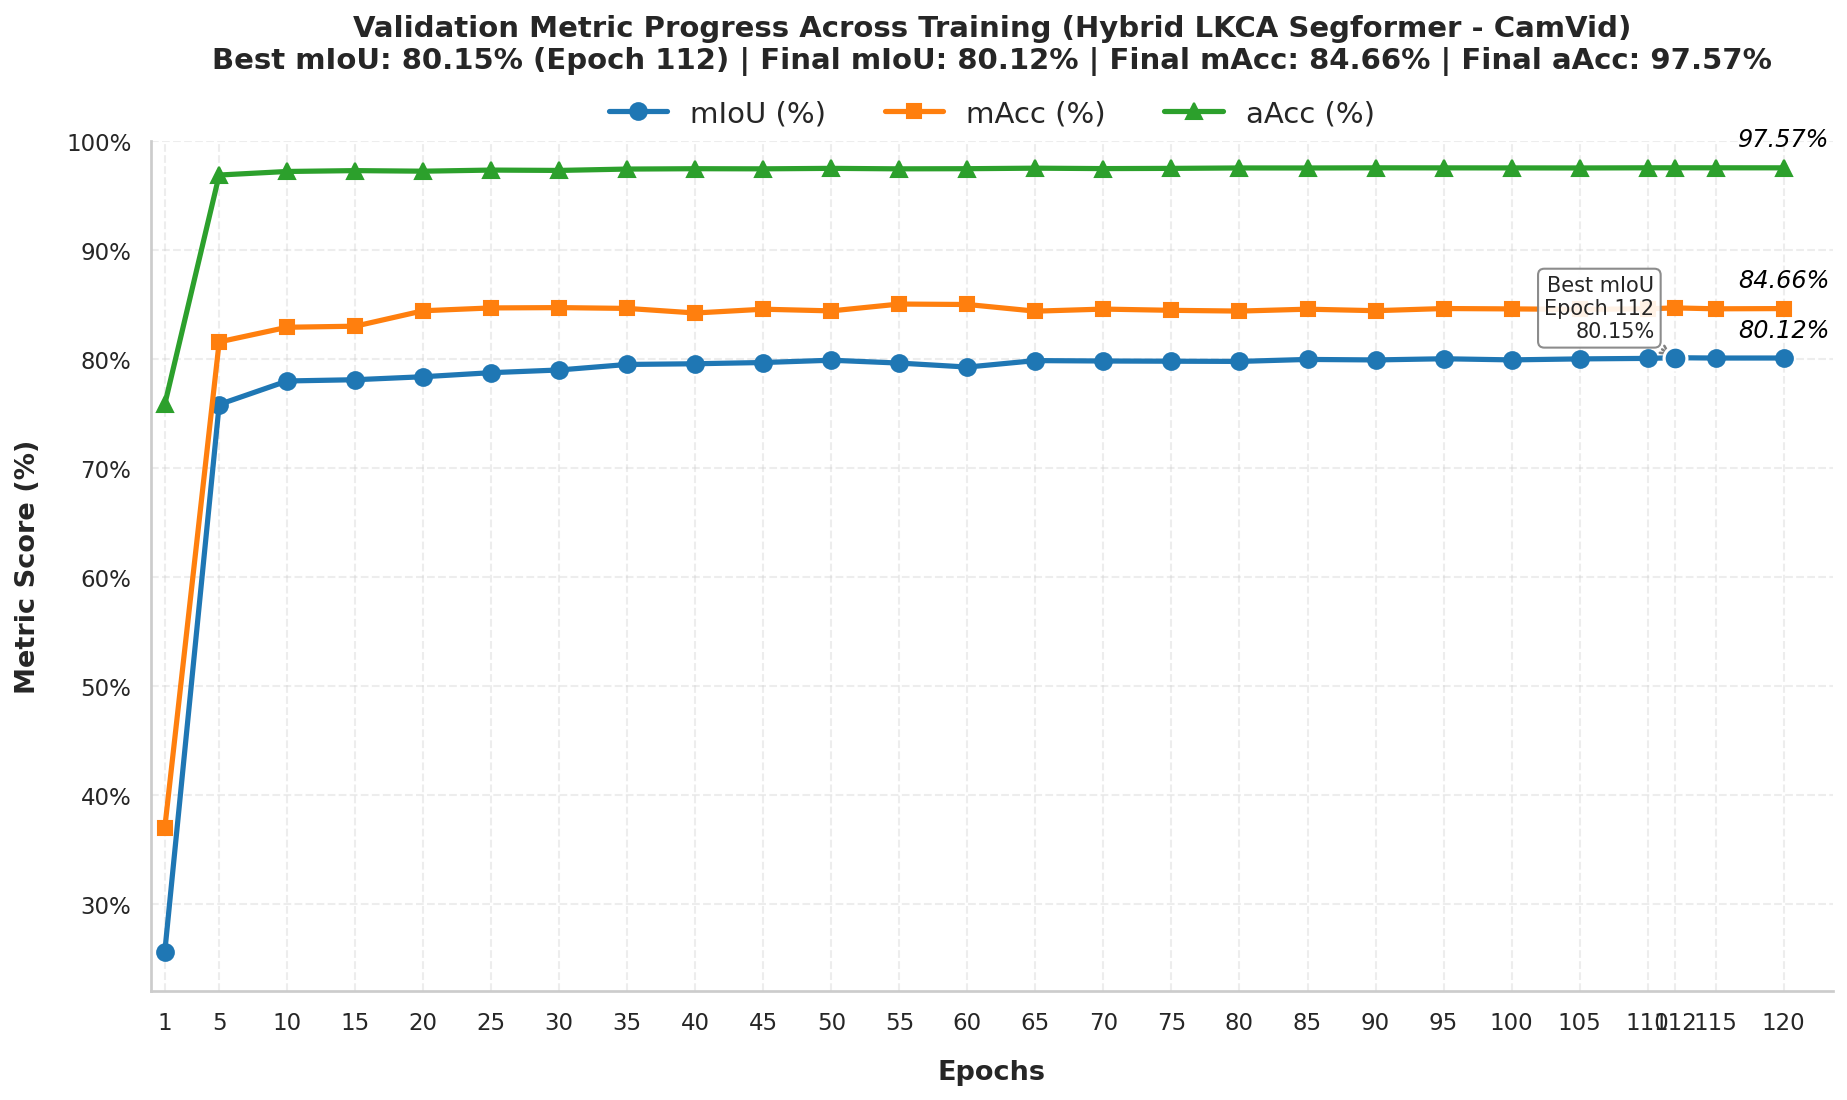

In [11]:
# ============================================================
# STEP 7: PRESENTATION-READY MULTI-METRIC PROGRESS GRAPH
# Target Architecture: Hybrid LKCA Segformer (MiT-B2)
# Target Dataset: CamVid
# Optimized for: Global Path Inheritance, Specific Epoch Intervals,
# and Strict Percentage Scaling for Publication
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = ["history"]
missing = [k for k in required_globals if k not in globals()]
if missing:
    raise NameError(f"Missing required variables from previous steps: {missing}")

if "val_miou" not in history or len(history["val_miou"]) == 0:
    raise ValueError("history['val_miou'] is empty. Run training (Step 5) before Step 7.")

# Inherit the centralized export directory securely from Step 1
FINAL_SAVE_DIR = globals().get("FINAL_SAVE_DIR", Path("/home/hrusikesh-nishank/Pictures/MiTB2_SegFormer_CamVid_CrossAtt/Results_Export"))
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[*] Presentation graph will be exported to: {FINAL_SAVE_DIR.resolve()}")

# ------------------------------------------------------------
# PREPARE EPOCHS & DATA
# ------------------------------------------------------------
all_epochs = history["epoch"]
PLOT_INTERVAL = 5

# Safe percentage converter (prevents 80% turning into 8000% if already scaled in Step 5)
def safe_pct(val):
    if pd.isna(val) or np.isnan(val): return 0.0
    return val * 100.0 if val <= 1.0 else float(val)

# Bulletproof Best Epoch Extraction
best_miou_raw = max(history["val_miou"])
best_idx = history["val_miou"].index(best_miou_raw)
best_miou = safe_pct(best_miou_raw)
best_miou_epoch = all_epochs[best_idx]

# Filter epochs to reduce visual clutter: Epoch 1, every nth epoch, best epoch, final epoch
filtered_epochs_set = set([e for e in all_epochs if e == 1 or e % PLOT_INTERVAL == 0] + [all_epochs[-1], best_miou_epoch])
filtered_epochs = sorted(list(filtered_epochs_set))

indices = [all_epochs.index(e) for e in filtered_epochs]

# Extract and convert to percentages for cleaner presentation
miou_scores = [safe_pct(history["val_miou"][i]) for i in indices]
macc_scores = [safe_pct(history["val_macc"][i]) for i in indices]
aacc_scores = [safe_pct(history["val_aacc"][i]) for i in indices]

final_miou = safe_pct(history["val_miou"][-1])
final_macc = safe_pct(history["val_macc"][-1])
final_aacc = safe_pct(history["val_aacc"][-1])
final_x = all_epochs[-1]

# ------------------------------------------------------------
# PLOT SETUP 
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12.5, 7.5)) 

color_miou = '#1f77b4'  # Blue
color_macc = '#ff7f0e'  # Orange
color_aacc = '#2ca02c'  # Green

ax.plot(filtered_epochs, miou_scores, marker='o', linewidth=2.5, markersize=8, label='mIoU (%)', color=color_miou)
ax.plot(filtered_epochs, macc_scores, marker='s', linewidth=2.5, markersize=7, label='mAcc (%)', color=color_macc)
ax.plot(filtered_epochs, aacc_scores, marker='^', linewidth=2.5, markersize=8, label='aAcc (%)', color=color_aacc)

# ------------------------------------------------------------
# AXIS LABELS
# ------------------------------------------------------------
ax.set_xlabel('Epochs', fontsize=13, fontweight='bold', labelpad=12)
ax.set_ylabel('Metric Score (%)', fontsize=13, fontweight='bold', labelpad=12)
ax.set_xticks(filtered_epochs)

# Force the Y-axis to display percent signs natively
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x)}%"))

# ------------------------------------------------------------
# BEST mIoU ANNOTATION 
# ------------------------------------------------------------
ax.scatter(best_miou_epoch, best_miou, s=120, zorder=5, color=color_miou, edgecolors='white', linewidth=1.5)

if best_miou_epoch <= (max(filtered_epochs) * 0.6):
    best_text_x = best_miou_epoch + 1.5
    best_ha = "left"
else:
    best_text_x = best_miou_epoch - 1.5
    best_ha = "right"

ax.annotate(
    f'Best mIoU\nEpoch {best_miou_epoch}\n{best_miou:.2f}%',
    xy=(best_miou_epoch, best_miou),
    xytext=(best_text_x, best_miou + 1.5),
    fontsize=10, ha=best_ha, va='bottom',
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
    arrowprops=dict(arrowstyle='->', color='gray', lw=1.2)
)

# ------------------------------------------------------------
# END-OF-LINE FINAL VALUE ANNOTATIONS (Floating above markers)
# ------------------------------------------------------------
# Placed slightly above the final points to match the target aesthetic
offset_y = 1.5

ax.text(final_x, final_miou + offset_y, f'{final_miou:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')
ax.text(final_x, final_macc + offset_y, f'{final_macc:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')
ax.text(final_x, final_aacc + offset_y, f'{final_aacc:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')

ax.set_xlim(left=0, right=max(all_epochs) + (max(all_epochs) * 0.03))
ax.set_ylim(top=100) 

# ------------------------------------------------------------
# STYLING & LEGEND
# ------------------------------------------------------------
# Center the legend horizontally above the plot area
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False, fontsize=14)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.3)
ax.spines['left'].set_linewidth(1.3)

ax.grid(True, linestyle='--', alpha=0.35)

title_main = "Validation Metric Progress Across Training (Hybrid LKCA Segformer - CamVid)"
title_sub = f"Best mIoU: {best_miou:.2f}% (Epoch {best_miou_epoch}) | Final mIoU: {final_miou:.2f}% | Final mAcc: {final_macc:.2f}% | Final aAcc: {final_aacc:.2f}%"

# Pushed the title up slightly to make room for the new legend position
ax.set_title(
    title_main + "\n" + title_sub,
    fontsize=14, fontweight='bold', pad=35
)

plt.tight_layout()

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------
# Directly save the single, unified presentation-ready graph
combined_graph_path = FINAL_SAVE_DIR / "presentation_metrics_progress_hybrid_lkca_camvid.png"
plt.savefig(combined_graph_path, dpi=600, bbox_inches='tight')
print(f"[*] Filtered presentation graph saved successfully to:\n{combined_graph_path.resolve()}")

plt.show()
plt.close()